In [86]:
from google.colab import files
uploaded = files.upload()

Saving SinalEletrico4.xlsx to SinalEletrico4 (1).xlsx


In [87]:
import pandas as pd
import io
df = pd.read_excel(io.BytesIO(uploaded['SinalEletrico4.xlsx']))
df

,tempo,medicao
0,0.000000,174.421356
1,0.000130,185.534300
2,0.000260,186.590495
3,0.000391,180.848334
4,0.000521,173.149044
...,...,...
764,0.099479,63.045193
765,0.099609,91.313887
766,0.099740,123.341038
767,0.099870,152.790034


In [88]:
ttt = df['tempo']
iii = df['medicao']

In [89]:
import numpy as np
zero_crossings = np.where(np.diff(np.sign(iii)))[0]
ttt[zero_crossings]

47     0.006120
112    0.014583
175    0.022786
240    0.031250
303    0.039453
368    0.047917
431    0.056120
496    0.064583
559    0.072786
624    0.081250
687    0.089453
752    0.097917
Name: tempo, dtype: float64

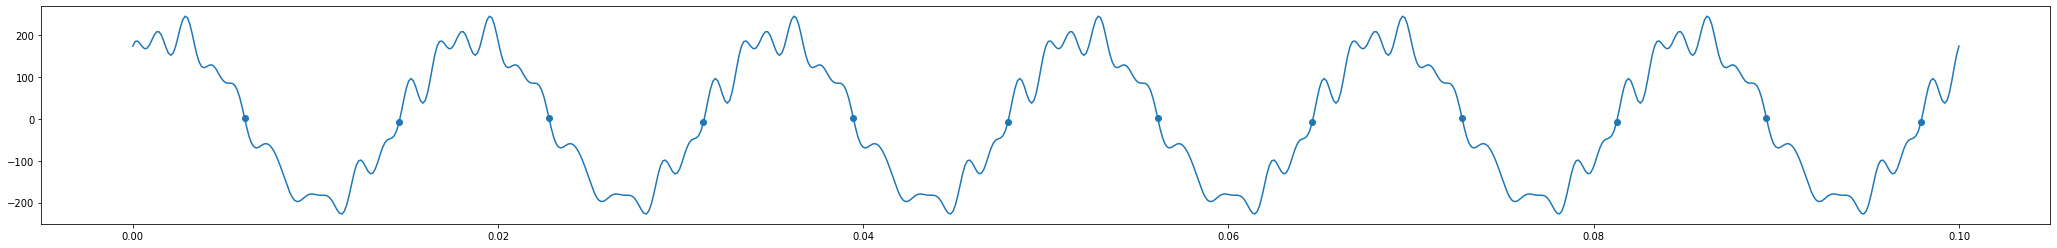

In [90]:
import matplotlib.pyplot as plt
plt.figure(figsize=(36,4))
plt.plot(ttt, iii)
plt.scatter(ttt[zero_crossings], iii[zero_crossings])


In [93]:
t_zero = ttt[zero_crossings]
periodo = t_zero[175] - t_zero[47]
periodo


0.016666666666666618

In [94]:
freqFund = 1 / periodo
freqFund

60.00000000000018

$$\frac{{\int {f\left( t \right)\sin \left( {h\left( {2\pi f} \right)t} \right)dt} }}{{\int {{{\sin }^2}\left( {h\left( {2\pi f} \right)t} \right)dt} }}$$

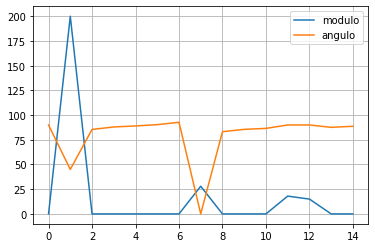

In [104]:
a = np.zeros(15)
b = np.zeros(15)

for h in range(15):
    num = np.trapz(iii*np.cos(h*2*np.pi*freqFund*ttt), ttt)
    den = np.trapz((np.cos(h*2*np.pi*freqFund*ttt))**2, ttt)
    a[h] = num/den
    if( h != 0 ):
        num = np.trapz(iii*np.sin(h*2*np.pi*freqFund*ttt), ttt)
        den = np.trapz((np.sin(h*2*np.pi*freqFund*ttt))**2, ttt)
        b[h] = num/den

hhh = np.arange(0,15,1)


modulo = np.sqrt( a**2 + b**2)


angulo = 180/np.pi * np.arctan2(a,b)

plt.plot(hhh, modulo, label='modulo')
plt.plot(hhh, angulo, label='angulo')
plt.legend()
plt.grid()

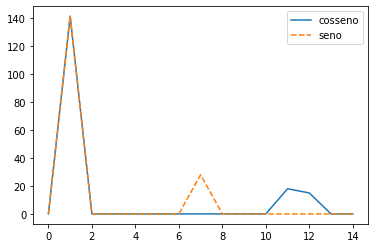

In [97]:
plt.plot(hhh, a, label='cosseno')
plt.plot(hhh, b, label='seno', ls='dashed')
plt.legend()

In [ ]:
plt.plot(ttt, iii*np.cos(h*2*np.pi*freqFund*ttt))